1. Import Required Libraries

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    hamming_loss
)

import tensorflow as tf

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

from tensorflow.keras.models import Sequential

from tensorflow.keras.layers import (
    Input,
    Embedding,
    Bidirectional,
    LSTM,
    Dense,
    Dropout,
    SpatialDropout1D,
    GlobalMaxPooling1D
)

from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau,
    ModelCheckpoint
)

2. Mount Google Drive and Load the Preprocessed Dataset

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
train = pd.read_csv("/content/drive/MyDrive/Data_Science/models/train_cleaned.csv")

print(train.shape)

train.head()

(159547, 10)


,id,comment_text,toxic,severe_toxic,obscene,threat,insult,identity_hate,clean_text,word_count
0,0000997932d777bf,Explanation\nWhy the edits made under my usern...,0,0,0,0,0,0,explanation why the edits made under my userna...,47
1,000103f0d9cfb60f,D'aww! He matches this background colour I'm s...,0,0,0,0,0,0,d aww ! he match this background colour i am s...,17
2,000113f07ec002fd,"Hey man, I'm really not trying to edit war. It...",0,0,0,0,0,0,hey man i am really not trying to edit war it ...,44
3,0001b41b1c6bb37e,"""\nMore\nI can't make any real suggestions on ...",0,0,0,0,0,0,more i can not make any real suggestion on imp...,116
4,0001d958c54c6e35,"You, sir, are my hero. Any chance you remember...",0,0,0,0,0,0,you sir are my hero any chance you remember wh...,15


3. Prepare Features, Labels, and Split the Dataset

In [ ]:
target_columns = [
    "toxic",
    "severe_toxic",
    "obscene",
    "threat",
    "insult",
    "identity_hate"
]

X = train["clean_text"]

y = train[target_columns]

In [ ]:
stratify_labels = (y.sum(axis=1) > 0).astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=stratify_labels
)

print(X_train.shape)
print(X_test.shape)

(127637,)
(31910,)


4. Tokenize Text and Pad Sequences

In [ ]:
VOCAB_SIZE = 50000
MAX_LEN = 150

tokenizer = Tokenizer(
    num_words=VOCAB_SIZE,
    oov_token="<OOV>"
)

tokenizer.fit_on_texts(X_train)

X_train_seq = tokenizer.texts_to_sequences(X_train)

X_test_seq = tokenizer.texts_to_sequences(X_test)

X_train_pad = pad_sequences(
    X_train_seq,
    maxlen=MAX_LEN,
    padding="post",
    truncating="post"
)

X_test_pad = pad_sequences(
    X_test_seq,
    maxlen=MAX_LEN,
    padding="post",
    truncating="post"
)

5. Load Pre-trained GloVe Word Embeddings

In [ ]:
glove_path = "/content/drive/MyDrive/Data_Science/models/glove.6B.100d.txt"

embeddings_index = {}

with open(glove_path, encoding="utf8") as f:

    for line in f:

        values = line.split()

        word = values[0]

        vector = np.asarray(values[1:], dtype="float32")

        embeddings_index[word] = vector

print("Total GloVe Words:", len(embeddings_index))

Total GloVe Words: 400000


6. Create the GloVe Embedding Matrix

In [ ]:
EMBEDDING_DIM = 100

embedding_matrix = np.zeros(
    (VOCAB_SIZE, EMBEDDING_DIM)
)

word_index = tokenizer.word_index

for word, index in word_index.items():

    if index >= VOCAB_SIZE:
        continue

    embedding_vector = embeddings_index.get(word)

    if embedding_vector is not None:

        embedding_matrix[index] = embedding_vector

print(embedding_matrix.shape)

(50000, 100)


7. Build and Compile the GloVe-based BiLSTM Model

In [ ]:
from tensorflow.keras.layers import (
    Input,
    Embedding,
    SpatialDropout1D,
    Bidirectional,
    LSTM,
    GlobalMaxPooling1D,
    Dense,
    Dropout,
    BatchNormalization
)

from tensorflow.keras.models import Model

inputs = Input(shape=(MAX_LEN,))

inputs = Input(shape=(MAX_LEN,))

x = Embedding(
    input_dim=VOCAB_SIZE,
    output_dim=EMBEDDING_DIM,
    weights=[embedding_matrix],
    trainable=False
)(inputs)

x = SpatialDropout1D(0.2)(x)

x = Bidirectional(
    LSTM(
        128,
        return_sequences=True
    )
)(x)

x = GlobalMaxPooling1D()(x)

x = BatchNormalization()(x)

x = Dense(
    128,
    activation="relu"
)(x)

x = Dropout(0.3)(x)

x = Dense(
    64,
    activation="relu"
)(x)

x = Dropout(0.2)(x)

outputs = Dense(
    6,
    activation="sigmoid"
)(x)

model = Model(inputs, outputs)

model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 150)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ embedding (Embedding)           │ (None, 150, 100)       │     5,000,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spatial_dropout1d               │ (None, 150, 100)       │             0 │
│ (SpatialDropout1D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ (None, 150, 256)       │       234,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_max_pooling1d            │ (None, 256)            │             0 │
│ (GlobalMaxPooling1D)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 6)              │           390 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,277,062 (20.13 MB)

 Trainable params: 276,550 (1.05 MB)

 Non-trainable params: 5,000,512 (19.08 MB)

In [ ]:
model.compile(

    optimizer=tf.keras.optimizers.Adam(1e-3),

    loss=tf.keras.losses.BinaryFocalCrossentropy(
        gamma=2
    ),

    metrics=[
        tf.keras.metrics.BinaryAccuracy(name="accuracy"),
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall"),
        tf.keras.metrics.AUC(name="auc")
    ]
)

8. Configure Callbacks and Train the GloVe-based BiLSTM Model

In [ ]:
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=4,
    restore_best_weights=True
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    verbose=1
)

checkpoint = ModelCheckpoint(
    "best_glove_bilstm.keras",
    save_best_only=True
)

In [ ]:
history = model.fit(

    X_train_pad,

    y_train,

    validation_split=0.2,

    epochs=20,

    batch_size=128,

    callbacks=[
        early_stop,
        reduce_lr,
        checkpoint
    ]
)

Epoch 1/20
798/798 ━━━━━━━━━━━━━━━━━━━━ 37s 35ms/step - accuracy: 0.9720 - auc: 0.9498 - loss: 0.0233 - precision: 0.6576 - recall: 0.4791 - val_accuracy: 0.9786 - val_auc: 0.9764 - val_loss: 0.0168 - val_precision: 0.7999 - val_recall: 0.5896 - learning_rate: 0.0010
Epoch 2/20
798/798 ━━━━━━━━━━━━━━━━━━━━ 26s 32ms/step - accuracy: 0.9787 - auc: 0.9748 - loss: 0.0168 - precision: 0.7894 - recall: 0.5641 - val_accuracy: 0.9795 - val_auc: 0.9813 - val_loss: 0.0152 - val_precision: 0.8400 - val_recall: 0.5741 - learning_rate: 0.0010
Epoch 3/20
798/798 ━━━━━━━━━━━━━━━━━━━━ 26s 32ms/step - accuracy: 0.9798 - auc: 0.9799 - loss: 0.0153 - precision: 0.8041 - recall: 0.5865 - val_accuracy: 0.9804 - val_auc: 0.9839 - val_loss: 0.0145 - val_precision: 0.8478 - val_recall: 0.5960 - learning_rate: 0.0010
Epoch 4/20
798/798 ━━━━━━━━━━━━━━━━━━━━ 41s 32ms/step - accuracy: 0.9809 - auc: 0.9833 - loss: 0.0142 - precision: 0.8186 - recall: 0.6120 - val_accuracy: 0.9810 - val_auc: 0.9849 - val_loss: 0.01

9. Visualize Training and Validation Loss

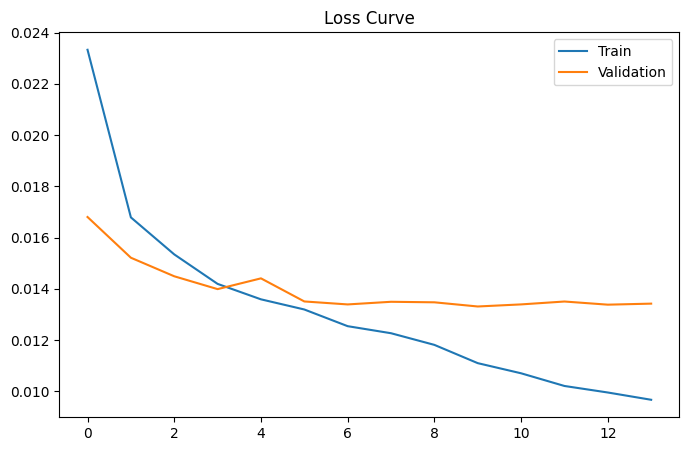

In [ ]:
plt.figure(figsize=(8,5))

plt.plot(history.history["loss"], label="Train")

plt.plot(history.history["val_loss"], label="Validation")

plt.legend()

plt.title("Loss Curve")

plt.show()

10. Generate Predictions and Evaluate Model Performance

In [ ]:
y_prob = model.predict(X_test_pad)

y_pred = (y_prob >= 0.5).astype(int)

998/998 ━━━━━━━━━━━━━━━━━━━━ 7s 6ms/step


In [ ]:
print("="*50)

print("Hamming Loss")
print(hamming_loss(y_test, y_pred))

print("="*50)

print("Micro Precision")
print(precision_score(y_test, y_pred, average="micro"))

print("="*50)

print("Micro Recall")
print(recall_score(y_test, y_pred, average="micro"))

print("="*50)

print("Micro F1")
print(f1_score(y_test, y_pred, average="micro"))

print("="*50)

print("Macro F1")
print(f1_score(y_test, y_pred, average="macro"))

print("="*50)

print("ROC AUC")
print(
    roc_auc_score(
        y_test,
        y_prob,
        average="macro"
    )
)

Hamming Loss
0.016859918520839862
Micro Precision
0.7943612615482638
Micro Recall
0.7202484113229347
Micro F1
0.7554915921830025
Macro F1
0.5879256474420443
ROC AUC
0.9838607014174326


11. Generate Classification Report for Each Toxicity Label

In [ ]:
for i, label in enumerate(target_columns):

    print("="*70)

    print(label.upper())

    print(
        classification_report(
            y_test[label],
            y_pred[:, i]
        )
    )

TOXIC
              precision    recall  f1-score   support

           0       0.97      0.99      0.98     28860
           1       0.84      0.75      0.79      3050

    accuracy                           0.96     31910
   macro avg       0.91      0.87      0.89     31910
weighted avg       0.96      0.96      0.96     31910

SEVERE_TOXIC
              precision    recall  f1-score   support

           0       0.99      1.00      1.00     31614
           1       0.57      0.15      0.24       296

    accuracy                           0.99     31910
   macro avg       0.78      0.57      0.62     31910
weighted avg       0.99      0.99      0.99     31910

OBSCENE
              precision    recall  f1-score   support

           0       0.99      0.99      0.99     30255
           1       0.82      0.80      0.81      1655

    accuracy                           0.98     31910
   macro avg       0.90      0.89      0.90     31910
weighted avg       0.98      0.98      0.98    